In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,confusion_matrix

In [ ]:
df = pd.read_csv("mnist784.csv")

print(df.head())
print(df.shape)

   pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  pixel9  \
0       0       0       0       0       0       0       0       0       0   
1       0       0       0       0       0       0       0       0       0   
2       0       0       0       0       0       0       0       0       0   
3       0       0       0       0       0       0       0       0       0   
4       0       0       0       0       0       0       0       0       0   

   pixel10  ...  pixel776  pixel777  pixel778  pixel779  pixel780  pixel781  \
0        0  ...         0         0         0         0         0         0   
1        0  ...         0         0         0         0         0         0   
2        0  ...         0         0         0         0         0         0   
3        0  ...         0         0         0         0         0         0   
4        0  ...         0         0         0         0         0         0   

   pixel782  pixel783  pixel784  class  
0         0         0

In [ ]:
X = df.drop("class", axis=1)
y = df["class"]

print(X.shape)
print(y.shape)

(70000, 784)
(70000,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
model = RandomForestClassifier(n_estimators=100, random_state=42)

model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy * 100, "%")

Accuracy: 96.72142857142858 %


In [ ]:
X_test_noisy = X_test.values + np.random.normal(
    0, 50, X_test.shape
)

X_test_noisy = np.clip(X_test_noisy, 0, 255)

In [ ]:
y_pred_noisy = model.predict(X_test_noisy)

noisy_accuracy = accuracy_score(y_test, y_pred_noisy)

print("Original Accuracy:", accuracy * 100, "%")
print("Accuracy After Adding Noise:", noisy_accuracy * 100, "%")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


Original Accuracy: 96.72142857142858 %
Accuracy After Adding Noise: 64.60714285714285 %


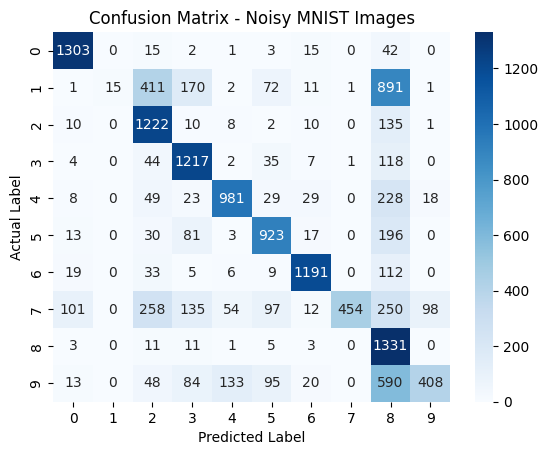

In [ ]:
cm = confusion_matrix(y_test, y_pred_noisy)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Noisy MNIST Images")
plt.show()

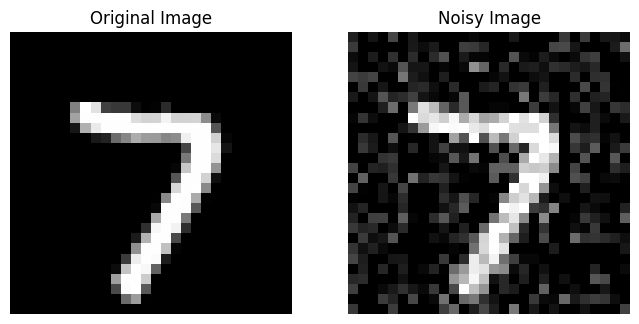

Actual Digit: 7
Original Prediction: 7
Noisy Prediction: 3


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:
i = 0

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(X_test.iloc[i].values.reshape(28, 28), cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(X_test_noisy[i].reshape(28, 28), cmap="gray")
plt.title("Noisy Image")
plt.axis("off")

plt.show()

print("Actual Digit:", y_test.iloc[i])
print("Original Prediction:", model.predict(X_test.iloc[[i]])[0])
print("Noisy Prediction:", model.predict(X_test_noisy[i:i+1])[0])

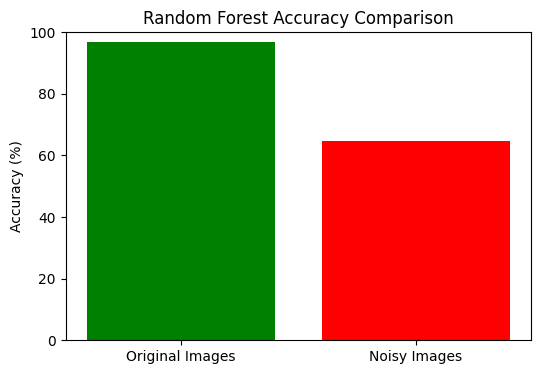

In [ ]:
plt.figure(figsize=(6, 4))

plt.bar(
    ["Original Images", "Noisy Images"],
    [accuracy * 100, noisy_accuracy * 100],
    color=['green', 'red']
)

plt.ylabel("Accuracy (%)")
plt.title("Random Forest Accuracy Comparison")
plt.ylim(0, 100)

plt.show()